# 🏭 Predictive Maintenance: Machine Failure Prediction (AI4I 2020)

## Hum kya karne wale hain?
Ek factory ki 10,000 machines ka data hai (temperature, speed, torque, tool wear). Humein **pehle se predict karna hai ki machine fail hogi ya nahi**, taaki breakdown se pehle repair ho sake.

**Steps:**
1. Data load karke check karna (missing, duplicate)
2. Imbalance samajhna (sirf ~3.4% machines fail hoti hain)
3. Leak karne wale columns hataana (TWF, HDF, PWF, OSF, RNF)
4. Naye columns banana (Power, Temp_diff, Strain)
5. Train/Test split aur scaling
6. 5 models test karna: Logistic, KNN, Naive Bayes, Decision Tree, Random Forest
7. Train aur Test dono ka Accuracy, Precision, Recall, F1 nikalna
8. Best model, confusion matrix aur important features
9. Bonus: Linear Regression (R²) aur K-Means

**Note:** Accuracy dhokha deti hai (sab "no failure" bol do to bhi 96% accuracy), isliye asli judge **F1** aur **Recall** hain.

Imports

In [1]:
import pandas as pd  # table ka kaam karne ke liye
import numpy as np  # maths ke kaam ke liye
import matplotlib.pyplot as plt  # graph banane ke liye
import seaborn as sns  # sundar graph (heatmap) ke liye
from sklearn.model_selection import train_test_split  # data ko train aur test me todne ke liye
from sklearn.preprocessing import StandardScaler  # columns ko same scale par laane ke liye
from sklearn.linear_model import LogisticRegression, LinearRegression  # Logistic aur Linear model
from sklearn.neighbors import KNeighborsClassifier  # KNN model
from sklearn.naive_bayes import GaussianNB  # Gaussian Naive Bayes model
from sklearn.tree import DecisionTreeClassifier  # Decision Tree model
from sklearn.ensemble import RandomForestClassifier  # Random Forest model
from sklearn.cluster import KMeans  # K-Means model
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score  # classification ke scores
from sklearn.metrics import r2_score, confusion_matrix  # R2 score aur confusion matrix

Data load

In [2]:
df = pd.read_csv('ai4i2020.csv')

In [3]:
df.shape

(10000, 14)

In [4]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [6]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

Imbalance check

In [8]:
print(df['Machine failure'].value_counts())  # kitni machine fail hui aur kitni nahi
print(df['Machine failure'].value_counts(normalize=True) * 100)  # wahi cheez percent me (imbalance dikhega)
print(df[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].sum())  # failure ke 5 reasons ka count, ye columns answer leak karte hain

Machine failure
0    9661
1     339
Name: count, dtype: int64
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


Cleaning aur naye columns

In [9]:
df.columns = ['UDI', 'Product_ID', 'Type', 'Air_temp', 'Process_temp', 'Rpm', 'Torque', 'Tool_wear', 'Failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']  # column ke naam chhote kar diye
df['Type'] = df['Type'].map({'L': 0, 'M': 1, 'H': 2})  # L M H letters ko 0 1 2 number banaya
df['Power'] = df['Torque'] * df['Rpm'] * 2 * np.pi / 60  # torque aur speed se power nikali (physics formula)
df['Temp_diff'] = df['Process_temp'] - df['Air_temp']  # process aur air temperature ka farak
df['Strain'] = df['Tool_wear'] * df['Torque']  # tool wear aur torque ko guna kiya
X = df.drop(['UDI', 'Product_ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF', 'Failure'], axis=1)  # faltu aur leak wale columns hata ke input X banaya
y = df['Failure']  # jo predict karna hai wo y
X.head()  # X ki pehli 5 rows dekhi

,Type,Air_temp,Process_temp,Rpm,Torque,Tool_wear,Power,Temp_diff,Strain
0,1,298.1,308.6,1551,42.8,0,6951.590560,10.5,0.0
1,0,298.2,308.7,1408,46.3,3,6826.722724,10.5,138.9
2,0,298.1,308.5,1498,49.4,5,7749.387543,10.4,247.0
3,0,298.2,308.6,1433,39.5,7,5927.504659,10.4,276.5
4,0,298.2,308.7,1408,40.0,9,5897.816608,10.5,360.0


Graph 1, Heatmap

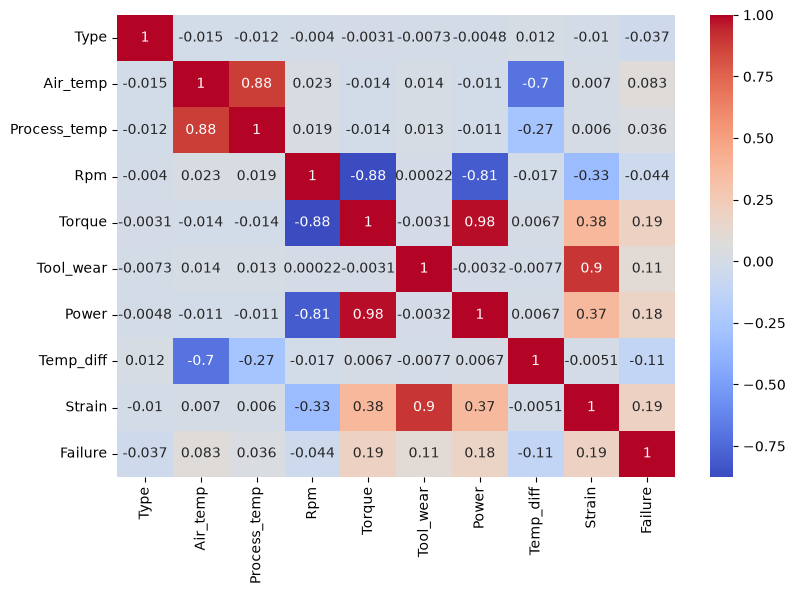

In [10]:
data = X.copy()  # X ki copy banayi
data['Failure'] = y  # copy me Failure column jod diya
plt.figure(figsize=(9, 6))  # graph ka size
sns.heatmap(data.corr(), annot=True, cmap='coolwarm')  # saare columns ka aapas ka relation (correlation) dikhaya
plt.show()  # graph dikhaya

Split aur Scaling

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)  # 80 percent train aur 20 percent test
scaler = StandardScaler()  # scaler banaya
X_train_s = scaler.fit_transform(X_train)  # train data se seekh ke train ko scale kiya
X_test_s = scaler.transform(X_test)  # test ko usi scale se badla
print(X_train_s.shape, X_test_s.shape)  # dono ka size dekha

(8000, 9) (2000, 9)


Model 1, Logistic Regression

In [12]:
lr = LogisticRegression(class_weight='balanced')  # Logistic Regression model banaya
lr.fit(X_train_s, y_train)  # model ko train data par sikhaya
tr = lr.predict(X_train_s)  # train par prediction
te = lr.predict(X_test_s)  # test par prediction
row_lr = [accuracy_score(y_train, tr), precision_score(y_train, tr), recall_score(y_train, tr), f1_score(y_train, tr), accuracy_score(y_test, te), precision_score(y_test, te), recall_score(y_test, te), f1_score(y_test, te)]  # train aur test ke 4-4 score list me rakhe

Model 2, KNN

In [15]:
knn = KNeighborsClassifier(n_neighbors=5)  # KNN model banaya, 5 padosi dekhega
knn.fit(X_train_s, y_train)  # model ko train data par sikhaya
tr = knn.predict(X_train_s)  # train par prediction
te = knn.predict(X_test_s)  # test par prediction
row_knn = [accuracy_score(y_train, tr), precision_score(y_train, tr), recall_score(y_train, tr), f1_score(y_train, tr), accuracy_score(y_test, te), precision_score(y_test, te), recall_score(y_test, te), f1_score(y_test, te)]  # train aur test ke 4-4 score list me rakhe

Model 3, Gaussian Naive Bayes

In [17]:
gnb = GaussianNB()  # Gaussian Naive Bayes model banaya
gnb.fit(X_train_s, y_train)  # model ko train data par sikhaya
tr = gnb.predict(X_train_s)  # train par prediction
te = gnb.predict(X_test_s)  # test par prediction
row_gnb = [accuracy_score(y_train, tr), precision_score(y_train, tr), recall_score(y_train, tr), f1_score(y_train, tr), accuracy_score(y_test, te), precision_score(y_test, te), recall_score(y_test, te), f1_score(y_test, te)]  # train aur test ke 4-4 score list me rakhe

Model 4, Decision Tree

In [ ]:
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=42)  # Decision Tree banaya, depth limit se overfitting kam hogi
dt.fit(X_train_s, y_train)  # model ko train data par sikhaya
tr = dt.predict(X_train_s)  # train par prediction
te = dt.predict(X_test_s)  # test par prediction
row_dt = [accuracy_score(y_train, tr), precision_score(y_train, tr), recall_score(y_train, tr), f1_score(y_train, tr), accuracy_score(y_test, te), precision_score(y_test, te), recall_score(y_test, te), f1_score(y_test, te)]  # train aur test ke 4-4 score list me rakhe